In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap
from matplotlib.transforms import ScaledTranslation

from imlff.common.util import proj_path

In [11]:
stability = np.array([
    [100.0,100.0,100.0,100.0,100.0,100.0,],
    [100.0,100.0,100.0,100.0,100.0,0.0,],
    [100.0,100.0,100.0,100.0,53.3,0.0,],
    [100.0,100.0,100.0,100.0,0.0,0.0,]
])
iterations = np.array([
    [10.0,4.7,3.4,2.2,1.7,1.2,],
    [10.0,4.5,3.3,2.1,1.7,1.4,],
    [10.0,4.5,3.3,2.1,1.9,1.4,],
    [10.0,4.6,3.3,2.2,1.9,1.3,]
])
titles = [
    'LTC=100fs', 
    'LTC=1ps', 
    'LTC=10ps', 
    'NVE'
]

tols = np.array([0.0,0.00032, 0.001, 0.0032, 0.01, 0.032])
mask = np.array([0,1,1,1,1,0], dtype=bool)
mask = np.array([0,1,1,1,1,1], dtype=bool)

In [12]:
len(stability)

4

~/imlff/../imlff-paper/figures/energy_conservation/tolerance_ltc__to__stability_iterations.pdf


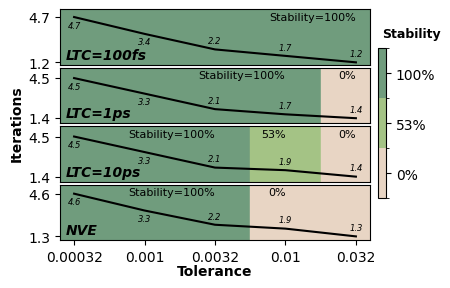

In [18]:
# Figure setup

col = True
# col = False

save = col and 1
padd = .2
alpha = 1.

ylim = 1.7, 5.3
lift_xlabel = True
lift_xlabel = False

cmap = plt.get_cmap('RdYlGn')
cmap = LinearSegmentedColormap.from_list('stability', [
    '#e8d5c4',  # warm beige (low)
    '#a8c686',  # sage green (mid)
    '#4a7c59',  # forest green (high)
])
cmap = LinearSegmentedColormap.from_list('stability', [
    '#e8d5c4',  # warm beige (low)
    '#a8c686',  # sage green (mid)
    "#709c7d",  # forest green (high)
])

m = len(stability)
n = sum(mask)
figsize=(5, .8*n)
figsize=(5, 2.6)
figsize=(4, 3)
fig, axs = plt.subplots(m**col, m**(not col), figsize=figsize, gridspec_kw=dict(wspace=0.05, hspace=0.05))

for i, ax in enumerate(axs):
    positions = np.arange(n)
    
    # Normalize for all axes
    norm = Normalize(vmin=0, vmax=100)
    sm = ScalarMappable(cmap=cmap, norm=norm)
    
    # Discrete colored background per position
    has_label = False
    for j, pos in enumerate(positions):
        stab = stability[i][mask][j]
        color = cmap(norm(stab))
        ax.axvspan(pos - 0.5, pos + 0.5, alpha=alpha, color=color, zorder=-1000)
        
        # if (has different predecessor)
        # or (has different successor)
        # or (is last and nothing has been labeled yet)
        if (j!=0 and stab!=stability[i][mask][j-1]) \
        or (j!=n-1 and stab!=stability[i][mask][j+1]) \
        or (j==n-1 and not has_label):
            ax.text(pos, 0.95, (not has_label)*'Stability=' + f'{stab:.0f}%',
                    ha='right', va='top', fontsize=8, color='black',
                    transform=ax.get_xaxis_transform(), zorder=10)
            has_label = True
        
    # Plot the main line
    ax.plot(positions, iterations[i][mask], zorder=1, color='black')
    vals = iterations[i][mask]
    mid = len(positions) // 2
    for j, pos in enumerate(positions):
        va, offset = ('top', -0.3) if j < mid else ('bottom', 0.3)
        ax.text(pos, vals[j] + offset, f'{vals[j]:.1f}',
                fontstyle='italic',
                ha='center', va=va, fontsize=6, color='black', zorder=10)
    
    # ticks, labels
    
    ax.set_ylim(*ylim)
    ax.set_xlim(-padd, n-1+padd)
    ax.set_xlabel('Tolerance', fontweight='bold', labelpad=-9*lift_xlabel)
    
    ax.set_xticks(positions)
    labels = ax.set_xticklabels(tols[mask])
    
    if lift_xlabel:
        mid = len(positions) // 2
        dx = -5 / 72  # points to inches
        labels[mid - 1].set_ha('right')
        labels[mid - 1].set_transform(labels[mid - 1].get_transform() + ScaledTranslation(-dx, 0, fig.dpi_scale_trans))
        labels[mid].set_ha('left')
        labels[mid].set_transform(labels[mid].get_transform() + ScaledTranslation(dx, 0, fig.dpi_scale_trans))
    
    # ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_yticks(range(int(ax.get_ylim()[0]), int(ax.get_ylim()[1]) + 1))
    ax.set_yticks([min(iterations[i][mask]), max(iterations[i][mask])])

# Only show x-ticks on the bottom axis
if col:
    for ax in axs[:-1]:
        ax.set_xticks([])
        ax.set_xlabel(None)
else:
    for ax in axs[1:]:
        ax.set_yticks([])
if False:
    # Add colorbar right center
    cbar_ax = fig.add_axes([0.92, 0.25, 0.02, 0.5])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Stability')
    cbar.set_ticks([0, 50, 100])
    cbar.set_ticklabels(['0%', '50%', '100%'])
else:
    # Get unique stability values across all axes
    all_stabs = np.unique(np.concatenate([stability[i][mask] for i in range(len(axs))]))
    colors = [cmap(norm(s)) for s in all_stabs]
    discrete_cmap = ListedColormap(colors)
    bounds = np.append(all_stabs - 0.5, all_stabs[-1] + 0.5)
    norm_discrete = BoundaryNorm(bounds, len(colors))
    sm_discrete = ScalarMappable(cmap=discrete_cmap, norm=norm_discrete)
    
    cbar_ax = fig.add_axes([0.92, 0.25, 0.02, 0.5])
    cbar = fig.colorbar(sm_discrete, cax=cbar_ax, ticks=all_stabs)
    
    centers = 0.5 * (bounds[:-1] + bounds[1:])
    cbar.set_ticks(centers)
    cbar.set_ticklabels([f'{s:.0f}%' for s in all_stabs])
    cbar.ax.set_title('Stability', fontsize=9, pad=8, ha='left', fontweight='bold')

if True:
    fig.text(0.0, 0.5, 'Iterations', fontweight='bold', va='center', ha='left', rotation='vertical')
    for ax, tit in zip(axs, titles):
        ax.text(0.02, 0.05, tit, transform=ax.transAxes,
                fontsize=10, fontstyle='italic', fontweight='bold', va='bottom', ha='left', zorder=10)

if save:
    plot_path = '../imlff-paper/figures/energy_conservation'
    pat = proj_path(f'{plot_path}/tolerance_ltc__to__stability_iterations.pdf')
    print(pat)
    plt.gcf().savefig(pat, bbox_inches="tight")
